# Exploratory Data Analysis Report: Book Catalogue and Pricing Analysis
The objective is to identify pricing patterns, examine relationships between book attributes, and develop insights that could support retail pricing, publishing decisions, and data-driven book purchasing.

**The analysis focuses on three business questions:**
- How does book pricing vary across categories?
- Is there an observable relationship between price and customer ratings?
- Can available product attributes provide a useful basis for predicting book prices?


In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

# For relationships plots
import matplotlib.pyplot as plt

# Libraries for building and evaluating the model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## 1. Data Acquisition
- Scrape data from 'Books to Scrape' website using requests and BeautifulSoup
- Retrieved 1000 book listings and individual product pages to obtain information
- Store scraped information to the pandas Dataset

In [ ]:
# To store retrieved data temporarly
data = []

for page in range(1, 51):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")

    for book in soup.find_all("article", class_="product_pod"):
        title = book.find('h3').find('a')['title']
        price = book.find('p', class_='price_color').text.strip()
        rating_words = book.find('p', class_='star-rating')['class'][1]
        stock = book.find('p', class_='instock availability').text.strip()
        book_link = book.find('h3').find('a')['href']

        book_url = 'https://books.toscrape.com/catalogue/' + book_link.replace('../', '')

        # Visit each page
        book_response = requests.get(book_url)

        book_soup = BeautifulSoup(book_response.text, 'html.parser')

        breadcrumb = book_soup.find('ul', class_='breadcrumb')

        category = breadcrumb.find_all('li')[2].text.strip()

        data.append({
            'Title': title,
            'Price': price,
            'Rating': rating_words,
            'Stock': stock,
            'Category': category
        })

    print(f"Page {page} completed")

    # Small delay between pages
    time.sleep(0.2)

# Create the dataset and populate with scraped data
books_df = pd.DataFrame(data)


Page 1 completed
Page 2 completed
Page 3 completed
Page 4 completed
Page 5 completed
Page 6 completed
Page 7 completed
Page 8 completed
Page 9 completed
Page 10 completed
Page 11 completed
Page 12 completed
Page 13 completed
Page 14 completed
Page 15 completed
Page 16 completed
Page 17 completed
Page 18 completed
Page 19 completed
Page 20 completed
Page 21 completed
Page 22 completed
Page 23 completed
Page 24 completed
Page 25 completed
Page 26 completed
Page 27 completed
Page 28 completed
Page 29 completed
Page 30 completed
Page 31 completed
Page 32 completed
Page 33 completed
Page 34 completed
Page 35 completed
Page 36 completed
Page 37 completed
Page 38 completed
Page 39 completed
Page 40 completed
Page 41 completed
Page 42 completed
Page 43 completed
Page 44 completed
Page 45 completed
Page 46 completed
Page 47 completed
Page 48 completed
Page 49 completed
Page 50 completed


In [13]:
# Display first 10 observations
books_df.head(10)

,Title,Price,Rating,Stock,Category,Clean_Title,Rating Numeric,Price_Category,In_Stock
0,A Light in the Attic,51.77,Three,In stock,Poetry,a light in the attic,3,High,1
1,Tipping the Velvet,53.74,One,In stock,Historical Fiction,tipping the velvet,1,High,1
2,Soumission,50.10,One,In stock,Fiction,soumission,1,High,1
3,Sharp Objects,47.82,Four,In stock,Mystery,sharp objects,4,High,1
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,History,sapiens a brief history of humankind,5,High,1
5,The Requiem Red,22.65,One,In stock,Young Adult,the requiem red,1,Medium,1
6,The Dirty Little Secrets of Getting Your Dream...,33.34,Four,In stock,Business,the dirty little secrets of getting your dream...,4,Medium,1
7,The Coming Woman: A Novel Based on the Life of...,17.93,Three,In stock,Default,the coming woman a novel based on the life of ...,3,Low,1
8,The Boys in the Boat: Nine Americans and Their...,22.60,Four,In stock,Default,the boys in the boat nine americans and their ...,4,Medium,1
9,The Black Maria,52.15,One,In stock,Poetry,the black maria,1,High,1


In [ ]:
# Save dataset as csv
books_df.to_csv('books.csv', index=False)

## 2. Data Cleaning
Firstly, inspect the dataset for duplicate records, missing values, invalid values, and unique values.



### 2.1. Inspection

In [8]:
print(f"Shape (rows, columns): {books_df.shape}")


print("\nDataset Information:")
books_df.info()

print(f"\nDuplicate Records: {books_df.duplicated().sum()}")

print(f"\nData types: \n{books_df.dtypes}")

print(f"\nMissing Values: {books_df.isnull().sum()}")

print(f"\nTotal number of books in each category: {books_df['Category'].value_counts()}")

print(f"\nTotal number of Categories: {books_df['Category'].nunique()}")

print(f"\nEmpty titles: {books_df['Title'].eq('').sum()}")


Shape (rows, columns): (1000, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Title     1000 non-null   str  
 1   Price     1000 non-null   str  
 2   Rating    1000 non-null   str  
 3   Stock     1000 non-null   str  
 4   Category  1000 non-null   str  
dtypes: str(5)
memory usage: 39.2 KB

Duplicate Records: 0

Data types: 
Title       str
Price       str
Rating      str
Stock       str
Category    str
dtype: object

Missing Values: Title       0
Price       0
Rating      0
Stock       0
Category    0
dtype: int64

Total number of books in each category: Category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens      

### 2.2. Cleaning
- Text preparation: Cleaning title and category for potential text-based analysis.
- Rating conversion: Converting text-based ratings into numeric values from 1 to 5.
- Price standardisation: Removing currency symbols and encoding artefacts, then converting prices into numeric values.
- Category standardisation: Removing unnecessary whitespace and ensuring consistent category labels.
- Stock preparation: Standardising stock descriptions and creating a binary In_Stock variable, where 1 indicates availability and 0 indicates otherwise.
- Missing-value handling: Identifying incomplete fields and the dataset has none, exclude handling of missing values.

In [14]:
# Clean title
books_df['Clean_Title'] = (
    books_df['Title']
    .str.lower()
    .str.replace(r'[^a-z0-9\s]', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Create numerical value for rating
rating_numeric = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}
books_df['Rating Numeric'] = books_df['Rating'].map(rating_numeric)

# Clean price
books_df['Price'] = (
    books_df['Price']
    .astype(str)
    .str.replace(r'[^0-9.]', '', regex=True)
    .astype(float)
)

# Clean category
books_df['Category'] = (
    books_df['Category']
    .astype(str)
    .str.strip()
)

# Create a pricing category
books_df['Price_Category'] = pd.cut(
    books_df['Price'],
    bins=[0, 20, 40, 60, 100],
    labels=['Low', 'Medium', 'High', 'Very High']
)

# Clean stock
books_df['Stock'] = (
    books_df['Stock']
    .astype(str)
    .str.replace('\n', '', regex=False)
    .str.strip()
)

# Create numerical value for stock. 1 = In stock, 0 = Out of stock
books_df['In_Stock'] = books_df['Stock'].str.contains('In stock', case=False, na=False).astype(int)

print(f"\nData types: \n{books_df.dtypes}")

books_df.head()


Data types: 
Title                  str
Price              float64
Rating                 str
Stock                  str
Category               str
Clean_Title            str
Rating Numeric       int64
Price_Category    category
In_Stock             int64
dtype: object


,Title,Price,Rating,Stock,Category,Clean_Title,Rating Numeric,Price_Category,In_Stock
0,A Light in the Attic,51.77,Three,In stock,Poetry,a light in the attic,3,High,1
1,Tipping the Velvet,53.74,One,In stock,Historical Fiction,tipping the velvet,1,High,1
2,Soumission,50.10,One,In stock,Fiction,soumission,1,High,1
3,Sharp Objects,47.82,Four,In stock,Mystery,sharp objects,4,High,1
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,History,sapiens a brief history of humankind,5,High,1


In [15]:
books_df.to_csv('clean_books_df.csv', index=False)

## 3. Data Visualization

### 3.1. Average price by category

In [21]:
genre_prices = (
    books_df.groupby('Category')['Price']
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

genre_prices.head()

Category
Suspense     58.33
Novels       54.81
Politics     53.61
Health       51.45
New Adult    46.38
Name: Price, dtype: float64

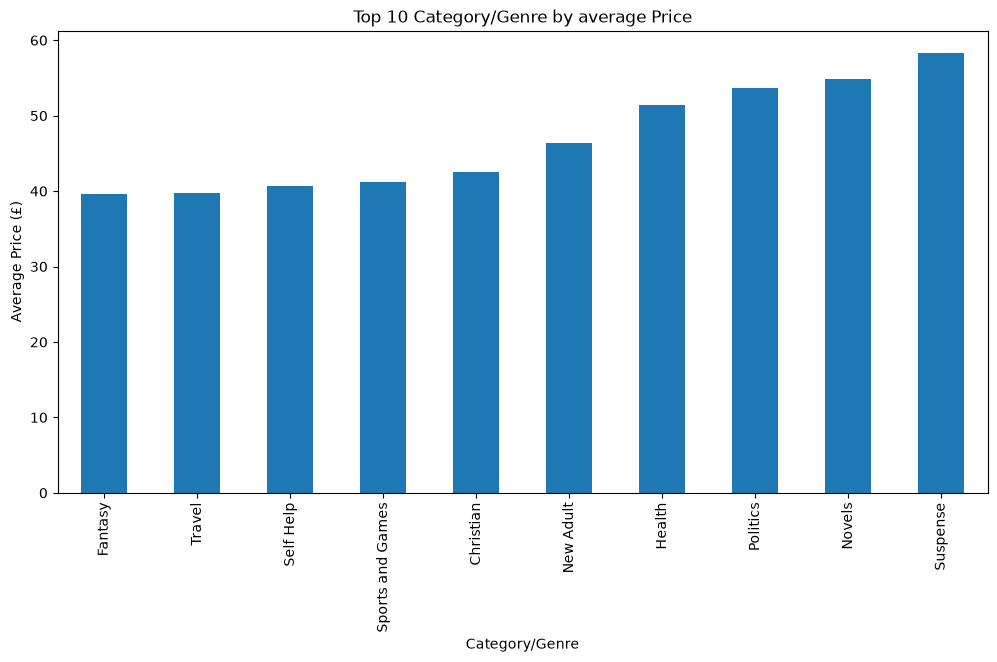

In [22]:
plt.figure(figsize=(12, 6))

genre_prices.head(10).sort_values().plot(kind='bar')

plt.xlabel('Category/Genre')
plt.ylabel('Average Price (£)')
plt.title('Top 10 Category/Genre by average Price')
plt.show()

### 3.2. Average Rating by Category/Genre

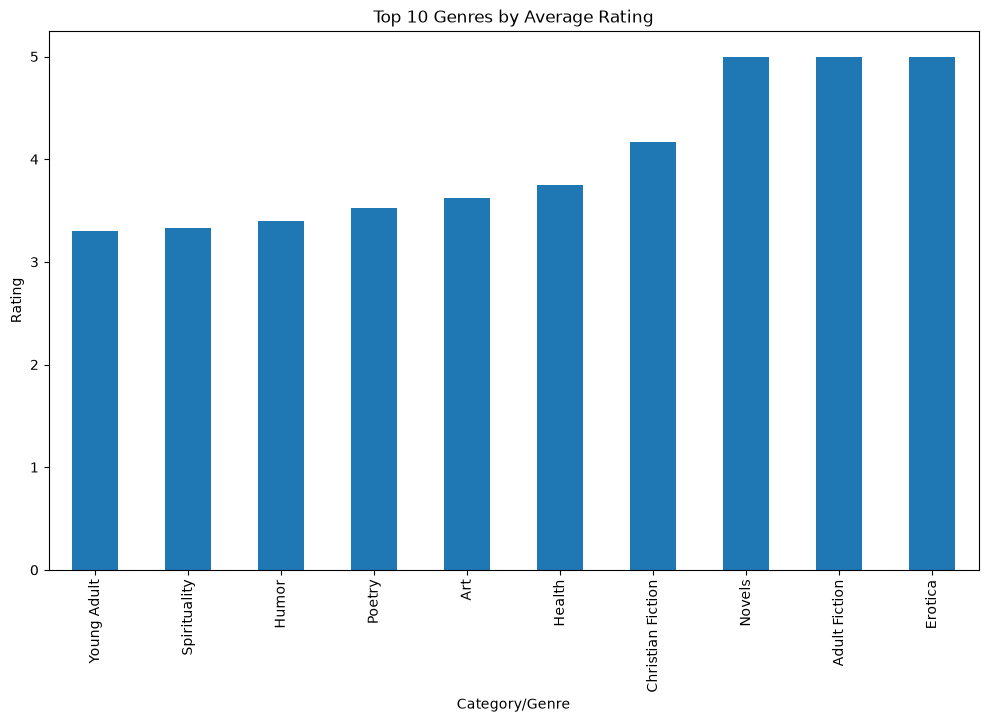

In [23]:
genre_ratings = (
    books_df
    .groupby('Category')['Rating Numeric']
    .mean()
    .sort_values(ascending=False)
)

genre_ratings.head(10)

plt.figure(figsize=(12, 7))

genre_ratings.head(10).sort_values().plot(
    kind='bar'
)

plt.xlabel('Category/Genre')
plt.ylabel('Rating')
plt.title('Top 10 Genres by Average Rating')

plt.show()

## Price and Rating

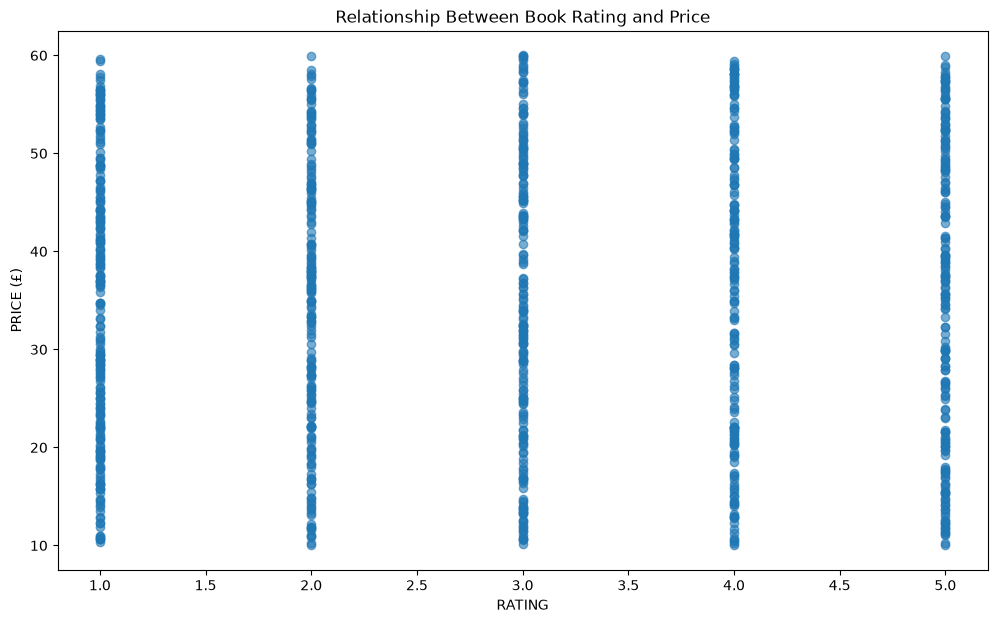

In [25]:
plt.figure(figsize=(12, 7))

plt.scatter(
    books_df['Rating Numeric'],
    books_df['Price'],
    alpha=0.6
)

plt.xlabel('RATING')
plt.ylabel('PRICE (£)')
plt.title('Relationship Between Book Rating and Price')

plt.show()

In [26]:
# Calculate the correlation
books_df[['Price', 'Rating Numeric']].corr()

,Price,Rating Numeric
Price,1.000000,0.028166
Rating Numeric,0.028166,1.000000


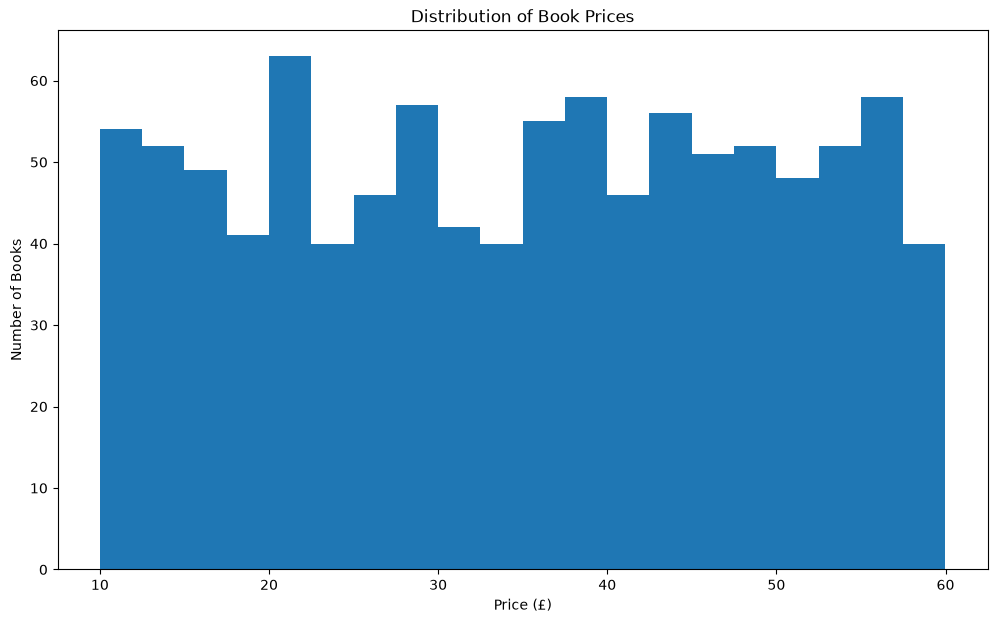

In [27]:

plt.figure(figsize=(12, 7))

plt.hist(books_df['Price'], bins=20)

plt.xlabel('Price (£)')
plt.ylabel('Number of Books')
plt.title('Distribution of Book Prices')

plt.show()

In [31]:
# 1. Overview of the dataset
print("Total books:", len(books_df))
print("Number of categories:", books_df["Category"].nunique())
print("Missing values:\n", books_df.isnull().sum())

# 2. Price statistics
print("\nPrice statistics:")
print(books_df["Price"].describe())

# 3. Mean and median price
print("Mean price: £", round(books_df["Price"].mean(), 2))
print("Median price: £", round(books_df["Price"].median(), 2))

# 4. Average price by category
print("\nAverage price by category:")
print(
    books_df.groupby("Category")["Price"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .round(2)
)

# 5. Rating distribution
print("\nRating distribution:")
print(books_df["Rating"].value_counts().sort_index())

print("\nRating percentages:")
print(
    (books_df["Rating"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

# 6. Stock availability
print("\nStock availability:")
print(books_df["In_Stock"].value_counts())

print("\nStock availability percentages:")
print(
    (books_df["In_Stock"].value_counts(normalize=True) * 100)
    .round(2)
)


Total books: 1000
Number of categories: 50
Missing values:
 Title             0
Price             0
Rating            0
Stock             0
Category          0
Clean_Title       0
Rating Numeric    0
Price_Category    0
In_Stock          0
dtype: int64

Price statistics:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64
Mean price: £ 35.07
Median price: £ 35.98

Average price by category:
                    count   mean  median
Category                                
Suspense                1  58.33   58.33
Novels                  1  54.81   54.81
Politics                3  53.61   52.65
Health                  4  51.45   51.34
New Adult               6  46.38   44.18
Christian               3  42.50   47.72
Sports and Games        5  41.17   44.84
Self Help               5  40.62   46.35
Travel                 11  39.79   38.95
Fantasy            